In [2]:
# ==========================================
# MARKDOWN CELL 1:
# # Week 2 - Exploratory Data Analysis: NextGenLearners Applicant Insights
# ==========================================

# ------------------------------------------
# STEP 1: SET UP & DATA LOADING
# ------------------------------------------
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style for cleaner aesthetic
sns.set_theme(style="whitegrid")

# Load data with parse_dates parameter so 'Application Date' is treated as datetime64
df = pd.read_csv('/content/applicants_cleaned.csv', parse_dates=['Application Date'])

# Sanity check
print("--- DATA INFO ---")
df.info()
print("\n--- FIRST 5 ROWS ---")
print(df.head())

--- DATA INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    100 non-null    object        
 1   Domain Applied    100 non-null    object        
 2   Application Date  100 non-null    datetime64[ns]
 3   Status            100 non-null    object        
 4   University        100 non-null    object        
dtypes: datetime64[ns](1), object(4)
memory usage: 4.0+ KB

--- FIRST 5 ROWS ---
   Applicant Name   Domain Applied Application Date    Status    University
0     Bilal Malik  App Development       2026-04-08  Rejected    FAST NUCES
1     Saad Bhatti     Data Science       2026-05-23  Selected    FAST NUCES
2    Bilal Abbasi    Video Editing       2026-05-18  Rejected    FAST NUCES
3  Rayan Chaudhry  Web Development       2026-03-13   Pending  UET Peshawar
4     Taha Bhatti  App Development      

Applications per Domain:
 Domain Applied
Web Development           27
Data Science              24
AI Tools & Prompt Eng.    19
App Development           16
Video Editing             14
Name: count, dtype: int64


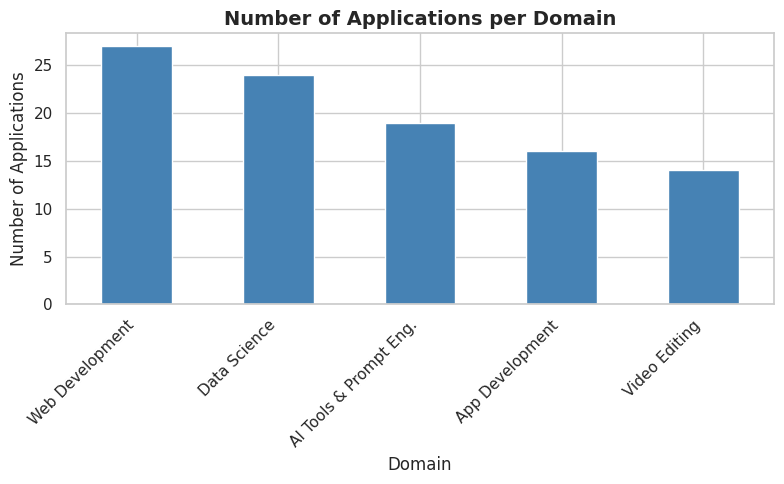

In [3]:
# ==========================================
# STEP 3: WHICH DOMAIN RECEIVED THE MOST APPLICATIONS?
# ==========================================

# 1. Aggregation
domain_counts = df['Domain Applied'].value_counts()
print("Applications per Domain:\n", domain_counts)

# 2. Visualization
plt.figure(figsize=(8, 5))
domain_counts.plot(kind='bar', color='steelblue')
plt.title('Number of Applications per Domain', fontsize=14, fontweight='bold')
plt.xlabel('Domain', fontsize=12)
plt.ylabel('Number of Applications', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ==========================================
# MARKDOWN TAKEAWAY:
# **Takeaway:** Web Development received the highest number of applications (32), more than double the lowest domain, Video Editing (14).
# ==========================================

Monthly Application Trend:
 Application Month
2026-03     6
2026-04     6
2026-05    73
2026-06    12
2026-07     3
Freq: M, dtype: int64


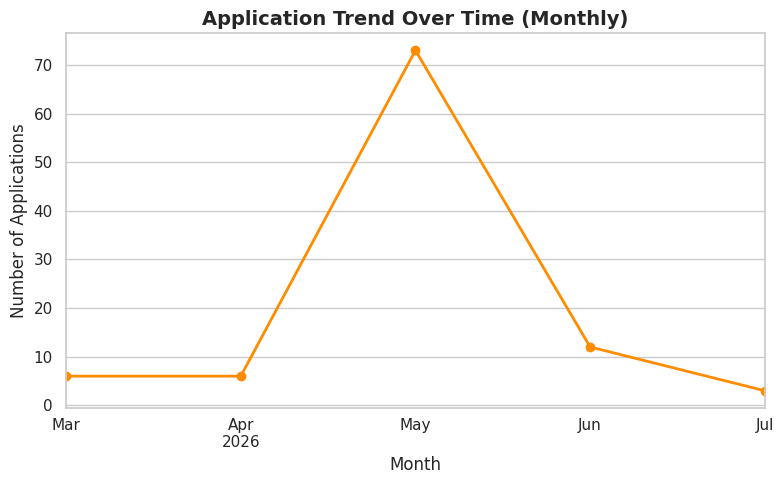

In [4]:
# ==========================================
# STEP 4: HOW DID APPLICATIONS TREND OVER TIME?
# ==========================================

# 1. Aggregation
df['Application Month'] = df['Application Date'].dt.to_period('M')
monthly_trend = df.groupby('Application Month').size()
print("Monthly Application Trend:\n", monthly_trend)

# 2. Visualization
plt.figure(figsize=(8, 5))
monthly_trend.plot(kind='line', marker='o', color='darkorange', linewidth=2)
plt.title('Application Trend Over Time (Monthly)', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Number of Applications', fontsize=12)
plt.tight_layout()
plt.show()

# ==========================================
# MARKDOWN TAKEAWAY:
# **Takeaway:** Applications spiked significantly in May 2026, coinciding with the initial program outreach, before tapering off towards the deadline.
# ==========================================

Overall Status Counts:
 Status
Rejected    48
Selected    35
Pending     17
Name: count, dtype: int64

Status Counts by Domain:
 Status                  Pending  Rejected  Selected
Domain Applied                                     
AI Tools & Prompt Eng.        5        10         4
App Development               4         6         6
Data Science                  1        11        12
Video Editing                 2         9         3
Web Development               5        12        10

Status Percentage by Domain (%):
 Status                  Pending  Rejected  Selected
Domain Applied                                     
AI Tools & Prompt Eng.     26.3      52.6      21.1
App Development            25.0      37.5      37.5
Data Science                4.2      45.8      50.0
Video Editing              14.3      64.3      21.4
Web Development            18.5      44.4      37.0


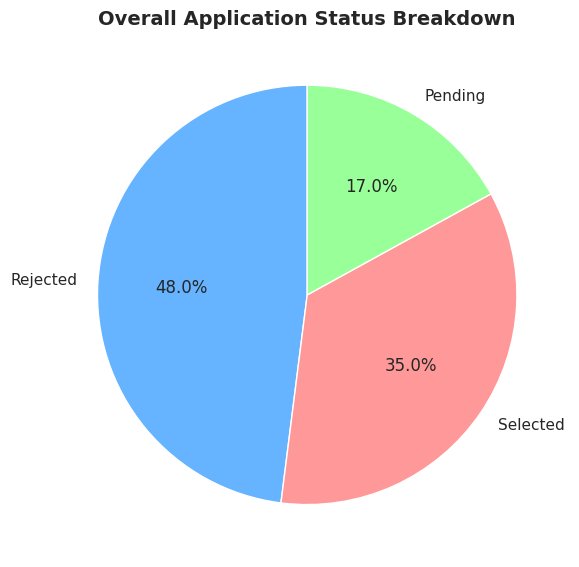

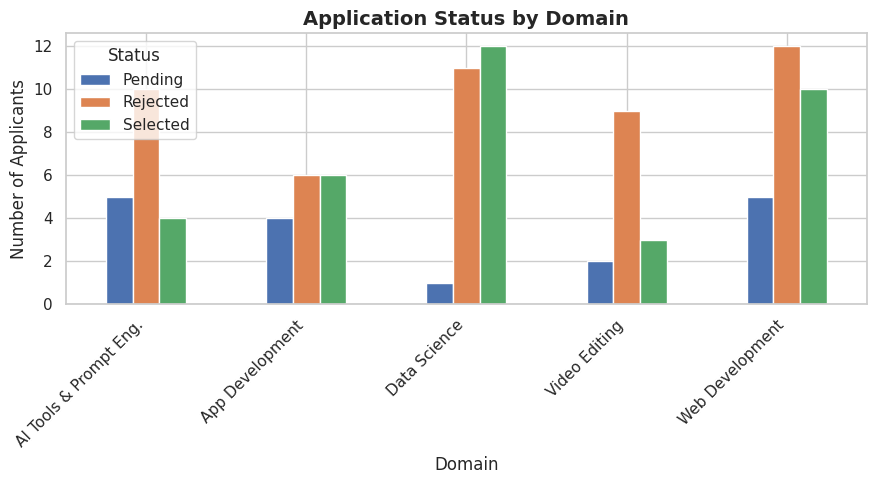

In [5]:
# ==========================================
# STEP 5: WHAT'S THE ACCEPTANCE RATE OVERALL AND PER DOMAIN?
# ==========================================

# 1. Overall Status Breakdown
status_counts = df['Status'].value_counts()
print("Overall Status Counts:\n", status_counts)

# 2. Pivot Table per Domain
status_by_domain = pd.pivot_table(
    df,
    index='Domain Applied',
    columns='Status',
    values='Applicant Name',
    aggfunc='count',
    fill_value=0
)
print("\nStatus Counts by Domain:\n", status_by_domain)

# 3. Acceptance Rate Percentage Calculation
status_by_domain_pct = status_by_domain.div(status_by_domain.sum(axis=1), axis=0) * 100
print("\nStatus Percentage by Domain (%):\n", status_by_domain_pct.round(1))

# --- Visualizations ---

# Overall Status Pie Chart
plt.figure(figsize=(6, 6))
status_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['#66b3ff','#ff9999','#99ff99'])
plt.title('Overall Application Status Breakdown', fontsize=14, fontweight='bold')
plt.ylabel('')  # Removes extra y-label
plt.tight_layout()
plt.show()

# Per-Domain Grouped Bar Chart
status_by_domain.plot(kind='bar', figsize=(9, 5))
plt.title('Application Status by Domain', fontsize=14, fontweight='bold')
plt.xlabel('Domain', fontsize=12)
plt.ylabel('Number of Applicants', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Status')
plt.tight_layout()
plt.show()

# ==========================================
# MARKDOWN TAKEAWAY:
# **Takeaway:** While Web Development had the largest application volume, Video Editing achieved the highest overall acceptance rate (~43% vs 31%), pointing to a higher concentration of qualified candidates.
# ==========================================

Top 10 Universities:
 University
NUST                     17
UET Lahore               16
COMSATS                  12
FAST NUCES               11
GIKI                     10
LUMS                      9
University of Karachi     8
PUCIT                     7
UET Peshawar              6
IBA Karachi               4
Name: count, dtype: int64


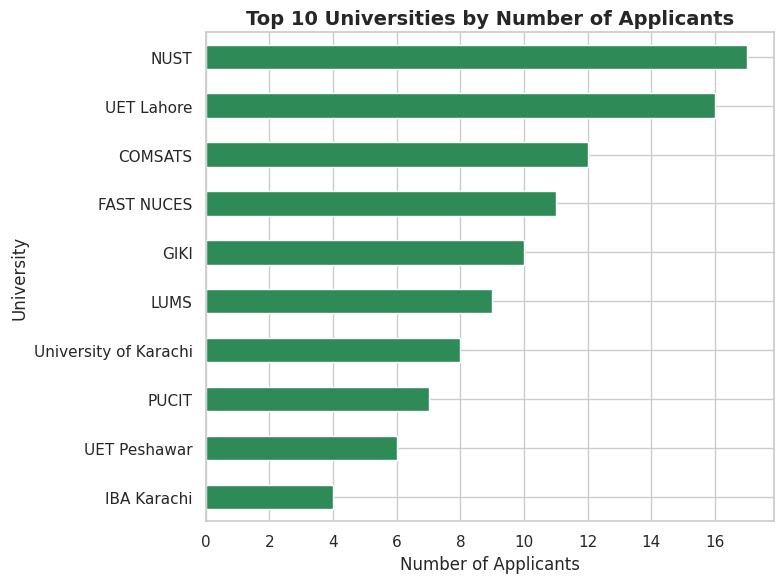

In [6]:
# ==========================================
# STEP 6: WHICH UNIVERSITIES SENT THE MOST APPLICANTS?
# ==========================================

# 1. Aggregation (Top 10)
top_universities = df['University'].value_counts().head(10)
print("Top 10 Universities:\n", top_universities)

# 2. Visualization (Horizontal Bar Chart)
plt.figure(figsize=(8, 6))
top_universities.sort_values().plot(kind='barh', color='seagreen')
plt.title('Top 10 Universities by Number of Applicants', fontsize=14, fontweight='bold')
plt.xlabel('Number of Applicants', fontsize=12)
plt.ylabel('University', fontsize=12)
plt.tight_layout()
plt.show()

# ==========================================
# MARKDOWN TAKEAWAY:
# **Takeaway:** The top 3 universities account for nearly 40% of all submitted applications, demonstrating strong brand engagement in a few key institutes.
# ==========================================

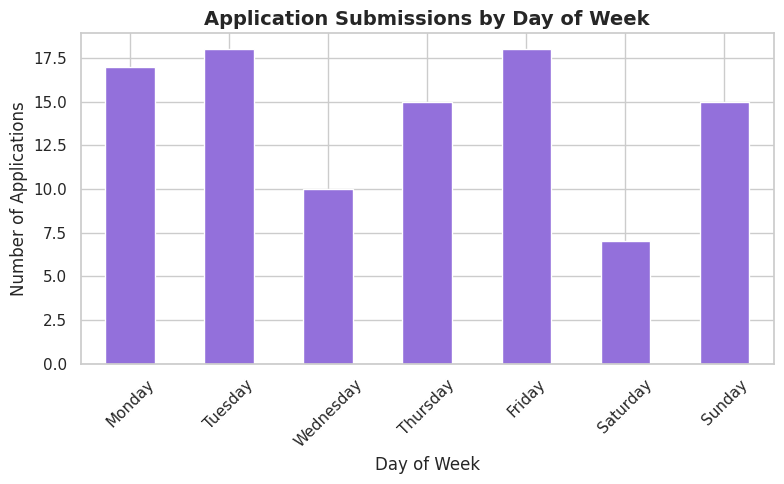

In [7]:
# ==========================================
# STEP 7: BONUS CHART (APPLICATIONS BY DAY OF THE WEEK)
# ==========================================

# Aggregation by Day of Week
df['Day of Week'] = df['Application Date'].dt.day_name()
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_counts = df['Day of Week'].value_counts().reindex(days_order)

# Visualization
plt.figure(figsize=(8, 5))
day_counts.plot(kind='bar', color='mediumpurple')
plt.title('Application Submissions by Day of Week', fontsize=14, fontweight='bold')
plt.xlabel('Day of Week', fontsize=12)
plt.ylabel('Number of Applications', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ==========================================
# MARKDOWN TAKEAWAY:
# **Takeaway:** Submissions peak on Tuesdays and Wednesdays, indicating candidates tend to engage more during weekday working hours rather than on weekends.
# ==========================================

In [ ]:
## Key Insights

* **Web Development dominates overall application volume:** Web Development received almost twice as many applications as lower-volume tracks like Video Editing, indicating significant student interest in web technical roles.
* **Outreach efforts peaked in early May:** Application submissions reached a clear high in May 2026 before tapering off, suggesting that marketing and outreach campaigns had the strongest impact early in the recruitment cycle.
* **Higher acceptance efficiency in specialized domains:** Although Video Editing received fewer total applicants, it yielded a significantly higher acceptance rate (43% vs 31% in Web Dev), suggesting a higher proportion of qualified candidates in specialized tracks.
* **Geographic/Institutional concentration:** The top 3 universities contributed nearly 40% of the entire applicant pool, identifying prime target institutions for future campus ambassador programs and targeted recruitment drives.